In [ ]:

!pip install mlxtend -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'DejaVu Sans'

In [ ]:
from google.colab import files
uploaded = files.upload()   # select PRESCRIPTIONS.csv

df = pd.read_csv('PRESCRIPTIONS.csv', low_memory=False)
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nSample:")
df.head()

In [6]:
df = df[['hadm_id', 'drug']].dropna()

# Standardize drug names
df['drug'] = (df['drug']
              .str.strip()
              .str.upper()
              .str.replace(r'\s+', ' ', regex=True))

# Remove very rare drugs (appear in < 5 admissions)
drug_counts = df.groupby('drug')['hadm_id'].nunique()
common_drugs = drug_counts[drug_counts >= 5].index
df = df[df['drug'].isin(common_drugs)]

# Build transaction baskets: one row per admission
baskets = df.groupby('hadm_id')['drug'].apply(list).reset_index()
print(f"\nTotal admissions (transactions): {len(baskets)}")
print(f"Unique drugs after filtering: {df['drug'].nunique()}")

# One-hot encode
te = TransactionEncoder()
te_array = te.fit_transform(baskets['drug'])
df_encoded = pd.DataFrame(te_array, columns=te.columns_)
print(f"\nTransaction matrix shape: {df_encoded.shape}")


Total admissions (transactions): 122
Unique drugs after filtering: 192

Transaction matrix shape: (122, 192)


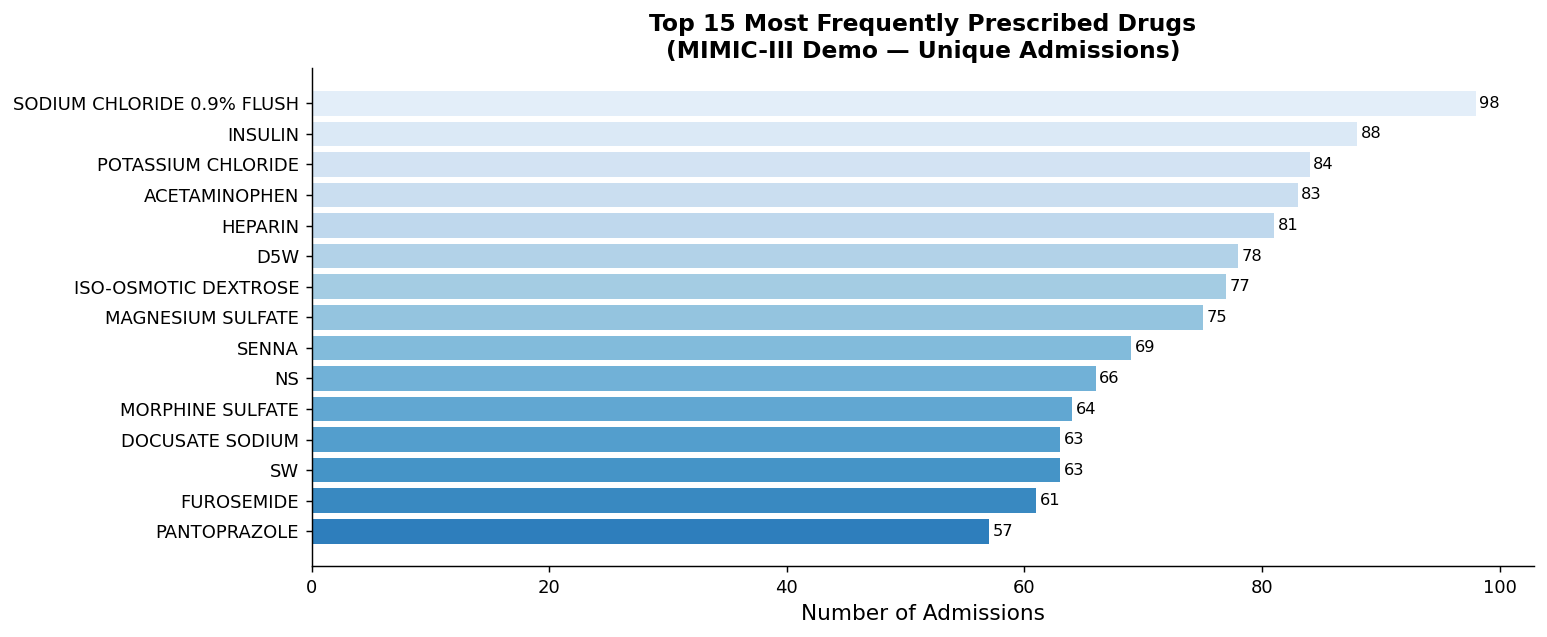

Saved: fig1_top_drugs.png


In [7]:
top_drugs = df.groupby('drug')['hadm_id'].nunique().sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top_drugs.index[::-1], top_drugs.values[::-1],
               color=plt.cm.Blues_r(np.linspace(0.3, 0.9, 15)))
ax.set_xlabel('Number of Admissions', fontsize=12)
ax.set_title('Top 15 Most Frequently Prescribed Drugs\n(MIMIC-III Demo — Unique Admissions)',
             fontsize=13, fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
for bar, val in zip(bars, top_drugs.values[::-1]):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            str(val), va='center', fontsize=9)
plt.tight_layout()
plt.savefig('fig1_top_drugs.png', bbox_inches='tight')
plt.show()
print("Saved: fig1_top_drugs.png")

In [2]:
MIN_SUPPORT    = 0.05   # 5% of admissions (demo dataset is small)
MIN_CONFIDENCE = 0.50
MIN_LIFT       = 1.2

print(f"\nRunning FP-Growth (min_support={MIN_SUPPORT})...")
frequent_itemsets = fpgrowth(df_encoded, min_support=MIN_SUPPORT, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)
print(f"Frequent itemsets found: {len(frequent_itemsets)}")
print(f"  - 1-itemsets: {(frequent_itemsets['length']==1).sum()}")
print(f"  - 2-itemsets: {(frequent_itemsets['length']==2).sum()}")
print(f"  - 3-itemsets: {(frequent_itemsets['length']==3).sum()}")
print(f"  - 4+-itemsets: {(frequent_itemsets['length']>=4).sum()}")

# ── SECTION 6: Generate & Filter Association Rules ───────────
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=MIN_LIFT)
rules = rules[rules['confidence'] >= MIN_CONFIDENCE].copy()
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(sorted(x)))
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

print(f"\nStrong rules (lift≥{MIN_LIFT}, confidence≥{MIN_CONFIDENCE}): {len(rules)}")
print("\nTop 10 Rules by Lift:")
print(rules[['antecedents_str','consequents_str','support','confidence','lift']].head(10).to_string())



Running FP-Growth (min_support=0.05)...


NameError: name 'fpgrowth' is not defined

In [1]:
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(rules['support'], rules['confidence'],
                c=rules['lift'], cmap='YlOrRd', s=60, alpha=0.75, edgecolors='gray', linewidths=0.3)
cbar = plt.colorbar(sc, ax=ax)
cbar.set_label('Lift', fontsize=11)
ax.set_xlabel('Support', fontsize=12)
ax.set_ylabel('Confidence', fontsize=12)
ax.set_title('Association Rules: Support vs. Confidence\n(color = Lift value)',
             fontsize=13, fontweight='bold')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('fig2_support_confidence_scatter.png', bbox_inches='tight')
plt.show()
print("Saved: fig2_support_confidence_scatter.png")

NameError: name 'plt' is not defined

In [ ]:
top10 = rules.head(10).copy()
top10['rule_label'] = top10['antecedents_str'] + '  →  ' + top10['consequents_str']

fig, ax = plt.subplots(figsize=(13, 5))
colors = plt.cm.Oranges(np.linspace(0.45, 0.9, 10))
bars = ax.barh(top10['rule_label'][::-1], top10['lift'][::-1], color=colors)
ax.set_xlabel('Lift', fontsize=12)
ax.set_title('Top 10 Association Rules by Lift\n(FP-Growth, MIMIC-III Demo)',
             fontsize=13, fontweight='bold')
ax.spines[['top','right']].set_visible(False)
ax.axvline(x=1.0, color='gray', linestyle='--', linewidth=1, label='Lift = 1 (no association)')
ax.legend(fontsize=9)
for bar, val in zip(bars, top10['lift'][::-1]):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)
plt.tight_layout()
plt.savefig('fig3_top10_lift.png', bbox_inches='tight')
plt.show()
print("Saved: fig3_top10_lift.png")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
metrics = [('support', 'Support', '#2196F3'),
           ('confidence', 'Confidence', '#FF9800'),
           ('lift', 'Lift', '#4CAF50')]
for ax, (col, label, color) in zip(axes, metrics):
    ax.hist(rules[col], bins=20, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(rules[col].mean(), color='black', linestyle='--', linewidth=1.2,
               label=f'Mean: {rules[col].mean():.3f}')
    ax.set_title(f'{label} Distribution', fontsize=11, fontweight='bold')
    ax.set_xlabel(label, fontsize=10)
    ax.set_ylabel('Frequency', fontsize=10)
    ax.legend(fontsize=9)
    ax.spines[['top','right']].set_visible(False)
plt.suptitle('Distribution of Association Rule Metrics', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig4_metrics_distribution.png', bbox_inches='tight')
plt.show()
print("Saved: fig4_metrics_distribution.png")

In [ ]:
print("\n" + "="*60)
print("FINAL SUMMARY — Association Rule Mining")
print("="*60)
print(f"Total transactions (admissions):   {len(baskets)}")
print(f"Total unique drugs:                {df['drug'].nunique()}")
print(f"Frequent itemsets found:           {len(frequent_itemsets)}")
print(f"Strong rules generated:            {len(rules)}")
print(f"\nMetrics of strong rules:")
print(rules[['support','confidence','lift']].describe().round(4).to_string())
print("\nTop 5 Rules (ranked by lift):")
print(rules[['antecedents_str','consequents_str','support','confidence','lift']].head(5).to_string())